# Dimensionless variables + XGBoost rerun

**Input:** `mstar_calibration.zip` (or its `features_with_folds.csv`) from the m* notebook, run on the updated preprocessing
output (it must contain `log10_sigma_Sm` and `flag_bipolar_post_peak`).

**Dimensionless variables** (k_B/e = 86.17 µV/K is the natural unit of thermopower):

| Symbol | Definition | Role |
|---|---|---|
| **s** | \|S\| / (k_B/e) | output |
| **s_SPB** | S_SPB(n, T; family m*) / (k_B/e) | physics baseline (input) |
| **Δs** | s − s_SPB | **target of the correction model** (default) |
| ln(s/s_SPB) | ln(\|S\|/S_SPB) | alternative multiplicative target (`TARGET = "log_ratio"`) |
| **ln(n/N_c)** | n over the effective density of states N_c = 2(2π m* k_B T/h²)^{3/2}: < 0 non-degenerate, > 0 degenerate | input |
| **τ** | T / 300 K | input (scattering / bipolar effects beyond SPB) |
| log₁₀ μ̃ | log₁₀[σ/(n e) in cm²/V·s], mobility from measured σ and n (not from S) | input, second set |
| mean valence e⁻ | composition-averaged valence electron count (already dimensionless) | input, second set |

**No leakage.** s_SPB and ln(n/N_c) depend on m*, so they are **recomputed inside every training fold** from the
family m* fitted on that fold's training papers. Post-peak bipolar points are removed from **training only**.
Scores are MAE/RMSE in s units and in µV/K, plus R² (R² is the same in both units, because s is just \|S\| rescaled).

## 0. Settings

In [4]:
INPUT = "features_with_folds.csv"      # or "mstar_calibration.zip"; you'll be asked to upload if missing
OUT_DIR = "dimensionless_xgb"
EXCLUDE_FAMILIES = ["Marcasite FeSb2"] # SPB not applicable (m* hit the search limit)
T_MIN = 100.0                          # K; drop points below this (SPB fits worst there). None = keep all
TARGET = "additive"                    # "additive": learn Δs = s − s_SPB (recommended) | "log_ratio": learn ln(s/s_SPB)
TRAIN_EXCLUDE_BIPOLAR = True           # remove post-peak bipolar points from TRAINING only
SAME_ROWS = True                       # compare input sets on identical rows (rows with QC-passed conductivity)
T_REF = 300.0                          # K, for τ = T / T_REF
INPUT_SETS = {
    "Hall-only": ["s_SPB", "ln_n_Nc", "tau"],
    "Hall + mobility + valence": ["s_SPB", "ln_n_Nc", "tau", "log10_mu", "val_mean"],
}
REFERENCE_DIMENSIONAL = {"Hall-only": 0.626, "Hall + mobility + valence": 0.670}   # R² of SPB+XGB from the previous run
RANK_SEEDS = None                      # None = all repeat seeds in the file
MIN_TRAIN_PAPERS = 3
M_BOUNDS = (0.05, 20.0)
XGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                  min_child_weight=5, reg_lambda=1.0, tree_method="hist", random_state=0, n_jobs=-1)
PERM_REPEATS = 3

In [5]:
import json, zipfile, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import quad
from scipy.special import expit
from scipy.optimize import minimize_scalar
import xgboost as xgb
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 220)
OUT = Path(OUT_DIR); OUT.mkdir(exist_ok=True)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
NEUTRAL, INK, INK2, GRID = "#b4b2ac", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight"})
KB, H_PL, M_E, E_CH = 1.380649e-23, 6.62607015e-34, 9.1093837015e-31, 1.602176634e-19
KBE_UV = KB / E_CH * 1e6               # k_B/e in µV/K = 86.17

## 1. Load

In [6]:
p = Path(INPUT)
if not p.exists():
    try:
        from google.colab import files
        p = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError(INPUT)
if p.suffix == ".zip":
    with zipfile.ZipFile(p) as z:
        z.extract("features_with_folds.csv", "."); p = Path("features_with_folds.csv")
d = pd.read_csv(p, low_memory=False)
if "log10_sigma_Sm" not in d or "flag_bipolar_post_peak" not in d:
    raise ValueError("No conductivity / bipolar columns: rerun the updated preprocessing and m* notebooks first.")
n0 = len(d)
d = d[~d["family"].isin(EXCLUDE_FAMILIES)]
if T_MIN is not None:
    d = d[d["T_K"] >= T_MIN]
d = d.reset_index(drop=True)
d["bip"] = d["flag_bipolar_post_peak"].astype(bool)
d["n_m3"] = 10 ** d["log10_n_cm3"] * 1e6
d["w"] = 1.0 / d.groupby("sample_key")["sample_key"].transform("size")
d["val_mean"] = d["el_n_valence_mean"]
d["log10_mu"] = np.log10(10 ** d["log10_sigma_Sm"] / (d["n_m3"] * E_CH) * 1e4)     # cm²/(V·s); NaN where σ missing
d["tau"] = d["T_K"] / T_REF
d["s"] = d["S_abs_uVK"] / KBE_UV
d_all = d.copy()
if SAME_ROWS:
    d = d[d["log10_mu"].notna()].reset_index(drop=True)
SEEDS = [int(c[6:]) for c in d.columns if c.startswith("fold_s")]
RANK_SEEDS = RANK_SEEDS or SEEDS
print(f"{n0} rows in file -> {len(d_all)} after exclusions (FeSb2: {EXCLUDE_FAMILIES}, T >= {T_MIN} K) -> "
      f"{len(d)} used ({d.sample_key.nunique()} samples, {d.SID.nunique()} papers) | bipolar {d.bip.mean():.1%} (training-only removal)")

Saving mstar_calibration (4).zip to mstar_calibration (4).zip
8358 rows in file -> 6980 after exclusions (FeSb2: ['Marcasite FeSb2'], T >= 100.0 K) -> 6415 used (870 samples, 233 papers) | bipolar 9.4% (training-only removal)


## 2. SPB, effective density of states and m* calibration

In [7]:
_eta = np.linspace(-30, 100, 2601)
_F = lambda j, e: quad(lambda x: x**j * expit(e - x), 0, max(e, 0) + 60, limit=200)[0]
_F12 = np.array([_F(0.5, e) for e in _eta]); _F1 = np.array([_F(1.0, e) for e in _eta]); _F0 = np.logaddexp(0, _eta)

def spb_seebeck_abs_uVK(n_m3, T_K, m_star=1.0):
    n_m3, T_K = np.asarray(n_m3, float), np.asarray(T_K, float)
    with np.errstate(divide="ignore", invalid="ignore"):
        F12 = n_m3 / (4 * np.pi * (2 * m_star * M_E * KB * T_K / H_PL**2) ** 1.5)
        eta = np.interp(np.log(F12), np.log(_F12), _eta)
        lo, hi = F12 < _F12[0], F12 > _F12[-1]
        eta = np.where(lo, np.log(F12 * 2 / np.sqrt(np.pi)), eta)
        e_hi = (1.5 * F12) ** (2 / 3); e_hi = (1.5 * F12 / (1 + np.pi**2 / (8 * e_hi**2))) ** (2 / 3)
        eta = np.where(hi, e_hi, eta)
        S = np.where(lo, 2 - eta, np.where(hi, np.pi**2 / (3 * eta),
                     2 * np.interp(eta, _eta, _F1) / np.interp(eta, _eta, _F0) - eta))
    return S * KBE_UV

def N_c(T_K, m_star):
    """Effective density of states (m^-3), parabolic band, spin degeneracy 2."""
    return 2 * (2 * np.pi * np.asarray(m_star) * M_E * KB * np.asarray(T_K) / H_PL**2) ** 1.5

def fit_mstar(g):
    w = g["w"].to_numpy(); S, n, T = g["S_abs_uVK"].to_numpy(), g["n_m3"].to_numpy(), g["T_K"].to_numpy()
    loss = lambda lm: np.sum(w * np.abs(S - spb_seebeck_abs_uVK(n, T, np.exp(lm)))) / w.sum()
    return float(np.exp(minimize_scalar(loss, bounds=np.log(M_BOUNDS), method="bounded", options={"xatol": 1e-4}).x))

def fold_mstar(train, *others):
    """Family m* fitted on `train` only; returns the m* array for train and every other frame."""
    m_glob = fit_mstar(train)
    fam = {f: fit_mstar(g) for f, g in train.groupby("family") if g["SID"].nunique() >= MIN_TRAIN_PAPERS}
    return [df["family"].map(fam).fillna(m_glob).to_numpy() for df in (train,) + others]

def add_dimensionless(df, m_star):
    """Adds the m*-dependent dimensionless columns (s_SPB, ln_n_Nc, target) for a given m* array."""
    df = df.copy()
    df["mstar"] = m_star
    df["s_SPB"] = spb_seebeck_abs_uVK(df["n_m3"], df["T_K"], m_star) / KBE_UV
    df["ln_n_Nc"] = np.log(df["n_m3"] / N_c(df["T_K"], m_star))
    df["y"] = df["s"] - df["s_SPB"] if TARGET == "additive" else np.log(df["s"] / df["s_SPB"])
    return df

def back(s_spb, yhat):
    return s_spb + yhat if TARGET == "additive" else s_spb * np.exp(yhat)

def splits_from(fold_col):
    fold_col = np.asarray(fold_col)
    return [(np.where(fold_col != k)[0], np.where(fold_col == k)[0]) for k in sorted(np.unique(fold_col))]
def mae(a, b): return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b)) ** 2)))
def r2(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return float(1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2))
def xgb_fit(X, y, w): return xgb.XGBRegressor(**XGB_PARAMS).fit(X, y, sample_weight=w)

## 3. The dimensionless dataset: ranges and distributions
Shown with the m* of the **primary split** (the `mstar_cv` column from the m* notebook), for description only.
Inside the cross-validation below, everything m*-dependent is recomputed per training fold.

,count,mean,std,min,1%,25%,50%,75%,99%,max
s = |S|/(k_B/e),6980.0,2.007,1.330,0.059,0.104,1.078,1.755,2.601,6.709,9.157
s_SPB,6980.0,2.005,1.651,0.009,0.028,0.708,1.803,2.591,7.106,8.252
Δs = s − s_SPB,6980.0,0.002,1.081,-5.989,-3.597,-0.441,0.137,0.587,2.329,7.570
ln(n/N_c),6980.0,0.677,2.449,-6.252,-5.105,-0.507,0.392,2.046,6.864,8.535
τ = T/300 K,6980.0,1.274,0.580,0.333,0.346,0.861,1.198,1.607,2.740,4.172
log₁₀ μ̃ (cm²/V·s),6415.0,1.684,0.934,-3.124,-0.852,1.163,1.725,2.227,3.561,4.708
mean valence e⁻,6980.0,5.941,1.320,2.621,3.156,5.067,5.600,6.440,9.333,9.400
"m* (m_e, primary split)",6980.0,0.937,0.689,0.098,0.098,0.575,0.821,1.018,3.467,5.166


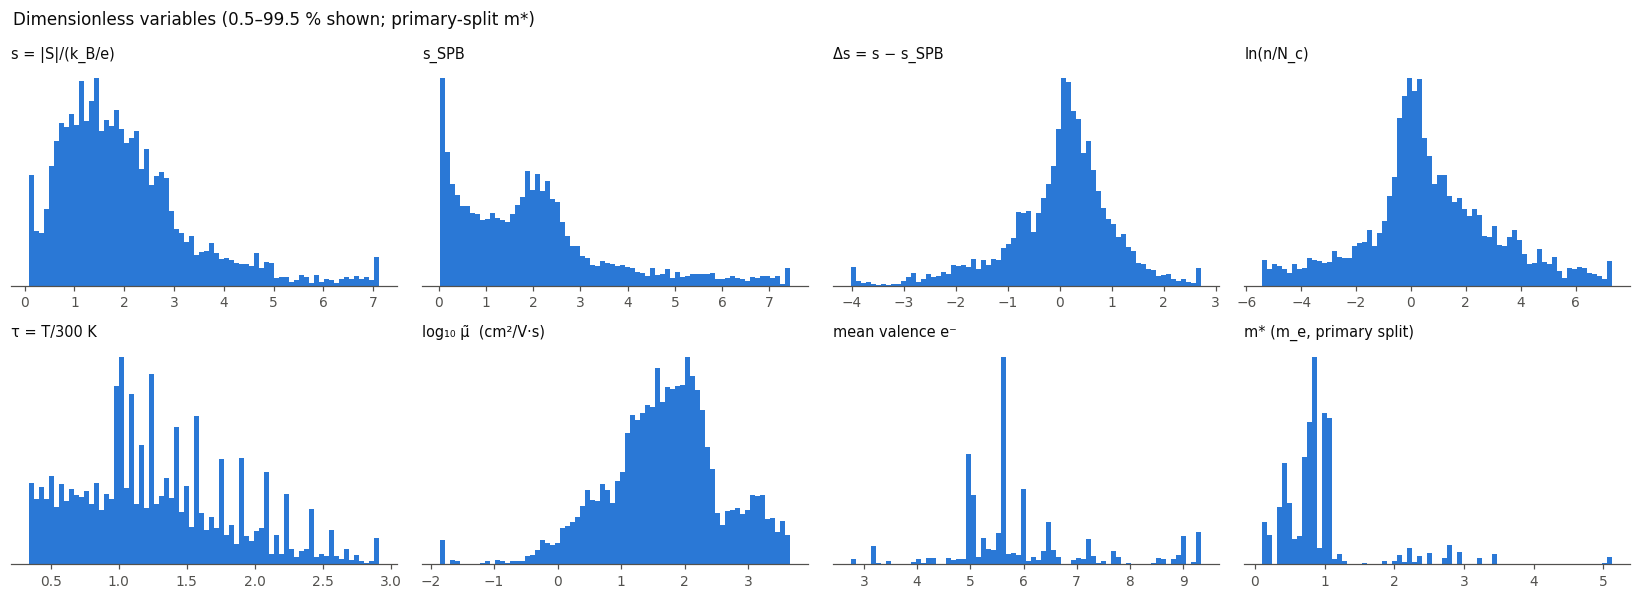

saved dimensionless_dataset.csv (m*-dependent columns use the primary split; refit per fold for modelling)


In [8]:
desc_df = add_dimensionless(d_all, d_all["mstar_cv"].to_numpy())
DIM_COLS = ["s", "s_SPB", "y", "ln_n_Nc", "tau", "log10_mu", "val_mean", "mstar"]
nice = {"s": "s = |S|/(k_B/e)", "s_SPB": "s_SPB", "y": "Δs = s − s_SPB" if TARGET == "additive" else "ln(s/s_SPB)",
        "ln_n_Nc": "ln(n/N_c)", "tau": "τ = T/300 K", "log10_mu": "log₁₀ μ̃  (cm²/V·s)", "val_mean": "mean valence e⁻",
        "mstar": "m* (m_e, primary split)"}
ranges = desc_df[DIM_COLS].describe(percentiles=[.01, .25, .5, .75, .99]).T.rename(index=nice)
display(ranges.round(3))
fig, ax = plt.subplots(2, 4, figsize=(15, 5.5)); ax = ax.ravel()
for a, c in zip(ax, DIM_COLS):
    v = desc_df[c].dropna()
    a.hist(v.clip(v.quantile(0.005), v.quantile(0.995)), bins=70, color=CAT[0])
    a.set_title(nice[c], loc="left", fontsize=9.5, color=INK); a.yaxis.set_visible(False); a.spines["left"].set_visible(False)
fig.suptitle("Dimensionless variables (0.5–99.5 % shown; primary-split m*)", x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_dimensionless_distributions.png"); plt.show()

keep = ["point_id", "study_id", "sample_key", "SID", "DOI", "composition", "host", "family", "broad_class", "group",
        "carrier_type", "T_K", "log10_n_cm3", "n_m3", "log10_sigma_Sm", "S_abs_uVK", "w", "flag_bipolar_post_peak",
        "fold"] + [f"fold_s{sd}" for sd in SEEDS] + DIM_COLS
desc_df[[c for c in keep if c in desc_df]].rename(columns={"y": "target_primary_split"}) \
    .to_csv(OUT / "dimensionless_dataset.csv", index=False)
print("saved dimensionless_dataset.csv (m*-dependent columns use the primary split; refit per fold for modelling)")

## 4. XGBoost on the dimensionless variables (all seeds × folds, split by paper)
For each fold: fit family m* on the training papers → compute s_SPB and ln(n/N_c) for train and test → train XGBoost on the target
(bipolar training points removed) → score on the held-out papers. Three models per input set:
- **SPB (family m*)**: s_SPB alone
- **SPB + XGB correction**: s_SPB plus the learned Δs (or times exp of the learned log ratio)
- **XGB direct**: predicts s from the same inputs **without** s_SPB. Note that ln(n/N_c) still carries m*.

Input ranking: drop-column (main), permutation and SHAP, as before.

In [9]:
def run(inputs):
    OOF = {sd: {m_: np.full(len(d), np.nan) for m_ in ("SPB", "SPB+XGB", "XGB_direct")} for sd in RANK_SEEDS}
    imp_rows = []
    no_spb = [c for c in inputs if c != "s_SPB"]
    for sd in RANK_SEEDS:
        for k, (tr, te) in enumerate(splits_from(d[f"fold_s{sd}"])):
            train_raw = d.iloc[tr]; train_raw = train_raw[~train_raw.bip] if TRAIN_EXCLUDE_BIPOLAR else train_raw
            m_tr, m_te = fold_mstar(train_raw, d.iloc[te])
            train, test = add_dimensionless(train_raw, m_tr), add_dimensionless(d.iloc[te], m_te)
            full = xgb_fit(train[inputs], train.y, train.w)
            yhat = full.predict(test[inputs]); base = mae(test.y, yhat)
            OOF[sd]["SPB"][te] = test.s_SPB
            OOF[sd]["SPB+XGB"][te] = back(test.s_SPB.to_numpy(), yhat)
            OOF[sd]["XGB_direct"][te] = xgb_fit(train[no_spb], train.s, train.w).predict(test[no_spb])
            contrib = full.get_booster().predict(xgb.DMatrix(test[inputs]), pred_contribs=True)[:, :-1]
            rng = np.random.default_rng(1000 * sd + k)
            for j_, f in enumerate(inputs):
                keep_ = [c for c in inputs if c != f]
                d_drop = mae(test.y, xgb_fit(train[keep_], train.y, train.w).predict(test[keep_])) - base
                perm = []
                for _ in range(PERM_REPEATS):
                    Xp = test[inputs].copy(); Xp[f] = rng.permutation(Xp[f].to_numpy())
                    perm.append(mae(test.y, full.predict(Xp)) - base)
                imp_rows.append({"seed": sd, "fold": k, "input": f, "drop_column": d_drop, "permutation": np.mean(perm),
                                 "shap": float(np.abs(contrib[:, j_]).mean())})
        print(f"  seed {sd} done ({time.time() - t0:.0f} s)")
    return OOF, pd.DataFrame(imp_rows)

def score(OOF):
    rows = []
    for sd in OOF:
        for sub, mask in (("all test points", np.ones(len(d), bool)), ("non-bipolar test points", ~d.bip.to_numpy())):
            y = d.s.to_numpy()[mask]
            for m_ in OOF[sd]:
                p_ = OOF[sd][m_][mask]
                rows.append({"seed": sd, "subset": sub, "model": m_, "MAE_s": mae(y, p_), "RMSE_s": rmse(y, p_),
                             "MAE_uVK": mae(y, p_) * KBE_UV, "RMSE_uVK": rmse(y, p_) * KBE_UV, "R2": r2(y, p_)})
    return pd.DataFrame(rows)

t0 = time.time(); RES = {}
for name, inputs in INPUT_SETS.items():
    print(f"== {name}: {inputs}")
    OOF_, imp_ = run(inputs)
    RES[name] = {"OOF": OOF_, "imp": imp_, "scores": score(OOF_)}

== Hall-only: ['s_SPB', 'ln_n_Nc', 'tau']
  seed 42 done (11 s)
  seed 7 done (22 s)
  seed 123 done (30 s)
  seed 2024 done (40 s)
  seed 31415 done (51 s)
== Hall + mobility + valence: ['s_SPB', 'ln_n_Nc', 'tau', 'log10_mu', 'val_mean']
  seed 42 done (66 s)
  seed 7 done (81 s)
  seed 123 done (96 s)
  seed 2024 done (113 s)
  seed 31415 done (128 s)


In [10]:
tab = []
for name, R_ in RES.items():
    t = R_["scores"].groupby(["subset", "model"])[["R2", "MAE_uVK", "RMSE_uVK", "MAE_s"]].agg(["mean", "std"])
    t.columns = [f"{a}_{b}" for a, b in t.columns]; tab.append(t.reset_index().assign(input_set=name))
tab = pd.concat(tab)
tab["model"] = tab["model"].map({"SPB": "SPB (family m*)", "SPB+XGB": "SPB + XGB correction", "XGB_direct": "XGB direct (no s_SPB)"})
tab = tab.set_index(["subset", "input_set", "model"]).sort_index()
print(f"Held-out scores, mean ± sd over {len(RANK_SEEDS)} seeds (target = {TARGET}; R² pooled over each seed's out-of-fold points)")
display(tab.round(3))
print("Previous run with dimensional inputs (all points incl. T < 100 K), R² of SPB + XGB:", REFERENCE_DIMENSIONAL,
      "\n-> compare like-for-like only if T_MIN = None; with T_MIN = 100 the data differ.")

rank = {}
for name, R_ in RES.items():
    a = R_["imp"].groupby("input").agg(drop_column=("drop_column", "mean"), drop_column_sd=("drop_column", "std"),
                                       permutation=("permutation", "mean"), permutation_sd=("permutation", "std"),
                                       shap=("shap", "mean"), shap_sd=("shap", "std"))
    a["share_of_fits_helpful"] = R_["imp"].assign(h=R_["imp"].drop_column > 0).groupby("input")["h"].mean()
    rank[name] = a.sort_values("drop_column", ascending=False)
    print(f"\nInput ranking, {name} (ΔMAE in target units; positive = the input helps on held-out papers):")
    display(rank[name].round(4))

Held-out scores, mean ± sd over 5 seeds (target = additive; R² pooled over each seed's out-of-fold points)


R2_mean  R2_std  MAE_uVK_mean  MAE_uVK_std  RMSE_uVK_mean  RMSE_uVK_std  MAE_s_mean  MAE_s_std
subset                  input_set                 model                                                                                                                
all test points         Hall + mobility + valence SPB (family m*)          0.362   0.033        63.775        2.620         91.865         2.355       0.740      0.030
                                                  SPB + XGB correction     0.668   0.018        45.534        0.829         66.263         1.806       0.528      0.010
                                                  XGB direct (no s_SPB)    0.669   0.013        45.870        0.772         66.175         1.322       0.532      0.009
                        Hall-only                 SPB (family m*)          0.362   0.033        63.775        2.620         91.865         2.355       0.740      0.030
                                                  SPB + XGB correction     0.618   0.006        50.258        0.595         71.092         0.585       0.583      0.007
                                                  XGB direct (no s_SPB)    0.590   0.012        51.963        1.353         73.598         1.042       0.603      0.016
non-bipolar test points Hall + mobility + valence SPB (family m*)          0.373   0.039        61.724        2.629         86.040         2.596       0.716      0.031
                                                  SPB + XGB correction     0.651   0.019        44.560        1.035         64.189         1.725       0.517      0.012
                                                  XGB direct (no s_SPB)    0.655   0.018        44.485        0.928         63.819         1.645       0.516      0.011
                        Hall-only                 SPB (family m*)          0.373   0.039        61.724        2.629         86.040         2.596       0.716      0.031
                                                  SPB + XGB correction     0.610   0.006        48.391        0.578         67.890         0.503       0.562      0.007
                                                  XGB direct (no s_SPB)    0.596   0.015        49.674        1.520         69.069         1.292       0.576      0.018

Previous run with dimensional inputs (all points incl. T < 100 K), R² of SPB + XGB: {'Hall-only': 0.626, 'Hall + mobility + valence': 0.67} 
-> compare like-for-like only if T_MIN = None; with T_MIN = 100 the data differ.

Input ranking, Hall-only (ΔMAE in target units; positive = the input helps on held-out papers):


,drop_column,drop_column_sd,permutation,permutation_sd,shap,shap_sd,share_of_fits_helpful
input,,,,,,,
tau,0.0432,0.0431,0.1001,0.0391,0.2225,0.0308,0.88
ln_n_Nc,0.0196,0.0291,0.1262,0.0685,0.2702,0.0409,0.64
s_SPB,0.0185,0.0298,0.0725,0.0424,0.2182,0.0410,0.64



Input ranking, Hall + mobility + valence (ΔMAE in target units; positive = the input helps on held-out papers):


,drop_column,drop_column_sd,permutation,permutation_sd,shap,shap_sd,share_of_fits_helpful
input,,,,,,,
log10_mu,0.0603,0.0363,0.1712,0.0441,0.2890,0.0302,0.92
val_mean,0.0286,0.0309,0.0627,0.0293,0.1588,0.0293,0.88
tau,0.0184,0.0178,0.0502,0.0185,0.1179,0.0196,0.88
s_SPB,0.0028,0.0095,0.0731,0.0458,0.2071,0.0454,0.60
ln_n_Nc,0.0017,0.0072,0.0513,0.0395,0.1727,0.0418,0.52


## 5. Figures

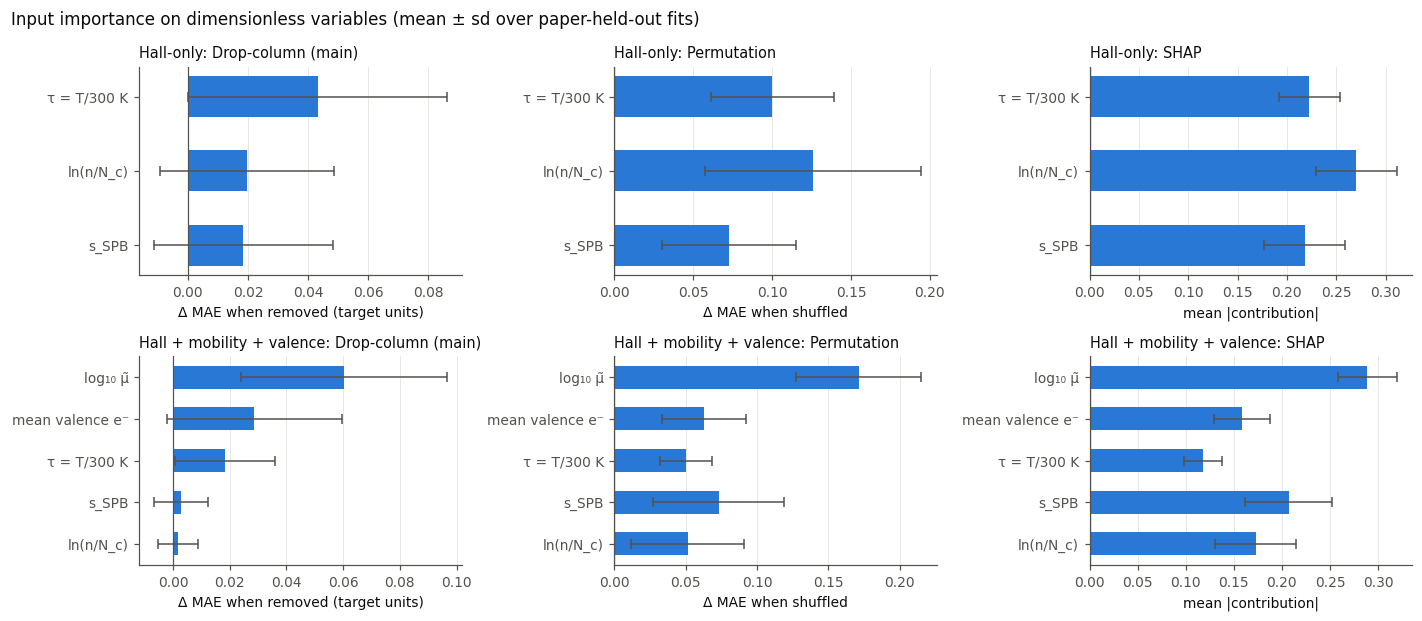

In [11]:
lab = {"s_SPB": "s_SPB", "ln_n_Nc": "ln(n/N_c)", "tau": "τ = T/300 K", "log10_mu": "log₁₀ μ̃", "val_mean": "mean valence e⁻"}
fig, axes = plt.subplots(len(RES), 3, figsize=(13, 1.3 + 0.55 * sum(len(v) for v in INPUT_SETS.values())), squeeze=False)
for row, (name, a_) in zip(axes, rank.items()):
    order = a_.index[::-1]; y = np.arange(len(order))
    for a, (col, sd_, ttl) in zip(row, [("drop_column", "drop_column_sd", "Drop-column (main)"),
                                        ("permutation", "permutation_sd", "Permutation"), ("shap", "shap_sd", "SHAP")]):
        a.barh(y, a_.loc[order, col], xerr=a_.loc[order, sd_], height=0.55, color=CAT[0], error_kw=dict(ecolor=INK2, lw=1, capsize=3))
        a.axvline(0, color=INK2, lw=0.8); a.set_yticks(y, [lab[i] for i in order])
        a.set_title(f"{name}: {ttl}", loc="left", fontsize=9.5, color=INK)
        a.xaxis.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True)
    row[0].set_xlabel("Δ MAE when removed (target units)"); row[1].set_xlabel("Δ MAE when shuffled"); row[2].set_xlabel("mean |contribution|")
fig.suptitle("Input importance on dimensionless variables (mean ± sd over paper-held-out fits)", x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_input_ranking_dimensionless.png"); plt.show()

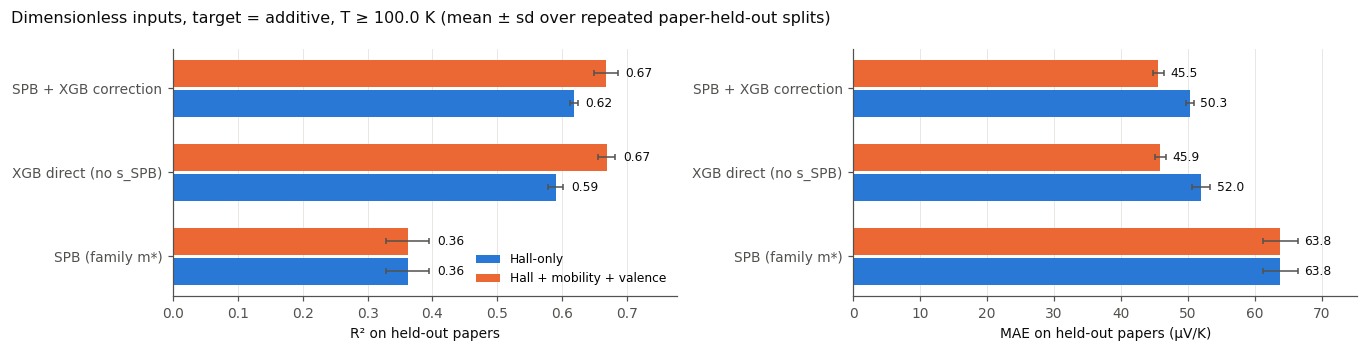

In [12]:
sub = tab.loc["all test points"].reset_index()
models = ["SPB (family m*)", "XGB direct (no s_SPB)", "SPB + XGB correction"]; sets = list(INPUT_SETS); w_ = 0.36
fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.2))
for a, met, xl in ((ax[0], "R2", "R² on held-out papers"), (ax[1], "MAE_uVK", "MAE on held-out papers (µV/K)")):
    for i_s, st in enumerate(sets):
        vals = [sub[(sub.input_set == st) & (sub.model == m_)][f"{met}_mean"].iloc[0] for m_ in models]
        errs = [sub[(sub.input_set == st) & (sub.model == m_)][f"{met}_std"].iloc[0] for m_ in models]
        y = np.arange(len(models)) + (i_s - 0.5) * w_
        a.barh(y, vals, xerr=errs, height=w_ - 0.04, color=CAT[i_s], label=st, error_kw=dict(ecolor=INK2, lw=1, capsize=2))
        pad = 0.012 if met == "R2" else 1.0
        for yi, v, e in zip(y, vals, errs):
            a.text(v + e + pad, yi, f"{v:.2f}" if met == "R2" else f"{v:.1f}", va="center", fontsize=8, color=INK)
    a.set_yticks(np.arange(len(models)), models); a.set_xlabel(xl); a.set_xlim(0, a.get_xlim()[1] * 1.08)
    a.xaxis.grid(True, color=GRID, lw=0.6); a.set_axisbelow(True)
ax[0].legend(frameon=False, fontsize=8, loc="lower right")
fig.suptitle(f"Dimensionless inputs, target = {TARGET}, T ≥ {T_MIN} K (mean ± sd over repeated paper-held-out splits)",
             x=0.01, ha="left", fontsize=10.5, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_r2_mae_dimensionless.png"); plt.show()

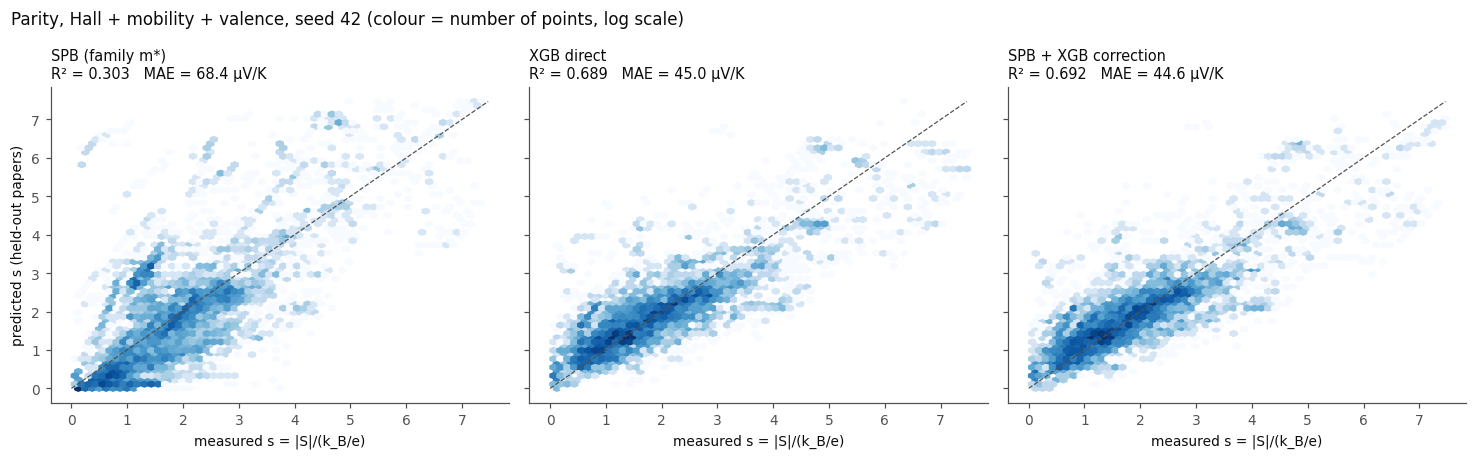

In [13]:
# parity plots, primary seed, best input set
best = max(RES, key=lambda n_: tab.loc[("all test points", n_, "SPB + XGB correction"), "R2_mean"])
sd0 = RANK_SEEDS[0]; lim = [0, np.quantile(d.s, 0.995) * 1.05]
fig, ax = plt.subplots(1, 3, figsize=(13.5, 4.2), sharex=True, sharey=True)
for a, (m_, ttl) in zip(ax, [("SPB", "SPB (family m*)"), ("XGB_direct", "XGB direct"), ("SPB+XGB", "SPB + XGB correction")]):
    p_ = RES[best]["OOF"][sd0][m_]
    hb = a.hexbin(d.s, p_, gridsize=60, extent=(lim[0], lim[1], lim[0], lim[1]), mincnt=1, cmap="Blues", bins="log")
    a.plot(lim, lim, color=INK2, lw=0.8, ls="--")
    a.set_title(f"{ttl}\nR² = {r2(d.s, p_):.3f}   MAE = {mae(d.s, p_) * KBE_UV:.1f} µV/K", loc="left", fontsize=9.5, color=INK)
    a.set_xlabel("measured s = |S|/(k_B/e)")
ax[0].set_ylabel("predicted s (held-out papers)")
fig.suptitle(f"Parity, {best}, seed {sd0} (colour = number of points, log scale)", x=0.01, ha="left", fontsize=11, color=INK)
plt.tight_layout(); plt.savefig(OUT / "fig_parity_dimensionless.png"); plt.show()

## 6. Save

In [14]:
tab.to_csv(OUT / "scores_dimensionless.csv"); ranges.to_csv(OUT / "dimensionless_ranges.csv")
for name, R_ in RES.items():
    tag = name.replace(" + ", "_").replace(" ", "_")
    rank[name].to_csv(OUT / f"input_ranking_{tag}.csv"); R_["imp"].to_csv(OUT / f"importance_per_fit_{tag}.csv", index=False)
    R_["scores"].to_csv(OUT / f"scores_per_seed_{tag}.csv", index=False)
report = {"settings": {"EXCLUDE_FAMILIES": EXCLUDE_FAMILIES, "T_MIN": T_MIN, "TARGET": TARGET, "T_REF": T_REF,
                       "TRAIN_EXCLUDE_BIPOLAR": TRAIN_EXCLUDE_BIPOLAR, "SAME_ROWS": SAME_ROWS, "INPUT_SETS": INPUT_SETS,
                       "XGB_PARAMS": XGB_PARAMS, "RANK_SEEDS": RANK_SEEDS, "xgboost_version": xgb.__version__},
          "rows_used": len(d), "samples": int(d.sample_key.nunique()), "papers": int(d.SID.nunique()),
          "scores": tab.round(4).reset_index().to_dict(orient="records"),
          "ranking_dropcol": {n_: a_["drop_column"].round(4).to_dict() for n_, a_ in rank.items()}}
(OUT / "dimensionless_report.json").write_text(json.dumps(report, indent=2, default=float))
import shutil
shutil.make_archive("dimensionless_xgb", "zip", OUT)
try:
    from google.colab import files
    files.download("dimensionless_xgb.zip")
except ImportError:
    print("zip at dimensionless_xgb.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>